# Эксперимент с классическими алгоритмами ML

Тип задачи — **мультиклассовая классификация** (3 класса: Healthy / Stressed / Critical).
Целевой признак — `crop_health`.

**Почему классификация:** таргет категориальный; задача — предсказать состояние культуры
по агрометеорологическим показателям (температура, влажность, осадки, влажность почвы,
pH, освещённость, удобрения).

**Метрики (обоснование):**
- **macro-F1** — основная. Классы несбалансированы (Healthy ≫ Stressed ≫ Critical),
  accuracy обманчива; macro-F1 усредняет F1 по классам без учёта размера и штрафует
  за плохое качество на редких классах.
- **balanced accuracy** — среднее recall по классам, устойчиво к дисбалансу.
- **accuracy** — для сравнения с baseline и общей картины.
- Confusion matrix — для анализа ошибок.

**Воспроизводимость:** `RANDOM_STATE = 42` везде (сплиты, модели, CV).

In [35]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from itertools import product
from sklearn.metrics import (f1_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, accuracy_score)

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [3]:
df = pd.read_csv("BIED_Smart_Agriculture_Dataset.csv")
print("Размер датасета:", df.shape)
print("\nБаланс классов crop_health:")
print(df["crop_health"].value_counts())
print("\nДоли:")
print(df["crop_health"].value_counts(normalize=True).round(4))

Размер датасета: (10000, 17)

Баланс классов crop_health:
crop_health
Healthy     7418
Stressed    2034
Critical     548
Name: count, dtype: int64

Доли:
crop_health
Healthy     0.7418
Stressed    0.2034
Critical    0.0548
Name: proportion, dtype: float64


In [4]:
df.head()

,timestamp,device_id,location,crop_type,season,temperature,humidity,rainfall,soil_moisture,soil_ph,light_intensity,fertilizer_used,irrigation_needed,crop_health,yield_estimate,pest_risk,anomaly_flag
0,2024-01-01 00:00:00,BD-MYM-002,Mymensingh,Rice,winter,23.16,59.08,0.00,41.64,6.63,16.0,61.58,0,Healthy,4.29,Low,0
1,2024-01-01 00:00:00,BD-MYM-005,Mymensingh,Wheat,winter,23.79,56.87,0.00,57.24,6.57,52.0,11.52,0,Healthy,3.25,Low,0
2,2024-01-01 00:00:00,BD-RAJ-003,Rajshahi,Rice,winter,19.64,62.09,0.00,51.01,5.64,79.0,31.35,0,Healthy,4.67,Low,0
3,2024-01-01 01:00:00,BD-MYM-002,Mymensingh,Tomato,winter,18.68,52.33,14.87,75.14,6.26,68.0,24.17,0,Healthy,35.56,Low,0
4,2024-01-01 01:00:00,BD-CHA-001,Chattogram,Rice,winter,20.75,59.96,0.00,64.59,6.01,31.0,85.57,0,Healthy,4.40,Low,0



Датасет содержит 10 000 наблюдений. Класс `Healthy` доминирует,
`Stressed` и особенно `Critical` представлены редко. Это подтверждает
необходимость macro-F1 и balanced accuracy: accuracy будет завышена за счёт
мажоритарного класса.

In [6]:
TARGET = "crop_health"
drop_cols = [TARGET, "anomaly_flag", "yield_estimate", "pest_risk",
             "irrigation_needed", "timestamp", "device_id"]

X = df.drop(columns=drop_cols)
y = df[TARGET]

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print("Числовые признаки:", num_cols)
print("Категориальные признаки:", cat_cols)
print("Форма X:", X.shape)

Числовые признаки: ['temperature', 'humidity', 'rainfall', 'soil_moisture', 'soil_ph', 'light_intensity', 'fertilizer_used']
Категориальные признаки: ['location', 'crop_type', 'season']
Форма X: (10000, 10)


После исключения 7 колонок (целевой признак,
четыре производных/итоговых показателя и два идентификатора ) в признаковом пространстве
осталось **10 признаков**:

- **7 числовых:** `temperature`, `humidity`, `rainfall`, `soil_moisture`,
  `soil_ph`, `light_intensity`, `fertilizer_used` — сырые сенсорные
  показатели;
- **3 категориальных:** `location`, `crop_type`, `season` — контекст
  выращивания.

Итоговая матрица `X` имеет размерность **(10000, 10)**, вектор цели `y`
содержит 3 класса (`Healthy`, `Stressed`, `Critical`). Все 10 признаков —
физически осмысленные и доступны в момент предсказания, что делает
постановку задачи корректной.

На этом формирование `X` и `y` завершено.

In [7]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full,
    random_state=RANDOM_STATE)

print("train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)
print("\nБаланс в train:\n", y_train.value_counts(normalize=True).round(4))
print("\nБаланс в val:\n",   y_val.value_counts(normalize=True).round(4))
print("\nБаланс в test:\n",  y_test.value_counts(normalize=True).round(4))

train: (6000, 10) | val: (2000, 10) | test: (2000, 10)

Баланс в train:
 crop_health
Healthy     0.7418
Stressed    0.2033
Critical    0.0548
Name: proportion, dtype: float64

Баланс в val:
 crop_health
Healthy     0.7420
Stressed    0.2035
Critical    0.0545
Name: proportion, dtype: float64

Баланс в test:
 crop_health
Healthy     0.7415
Stressed    0.2035
Critical    0.0550
Name: proportion, dtype: float64


Выборки: train = 6000, val = 2000, test = 2000. Доли классов во всех частях
совпадают (стратификация сработала). Тест изолирован и будет использован
ровно один раз — для финальной оценки лучшей модели.

## Baseline-модели

Для сравнения используем две «наивные» стратегии `DummyClassifier`:
- **most_frequent** — всегда предсказывает самый частый класс (Healthy). Нижняя граница.
- **stratified** — случайное предсказание пропорционально частотам классов.

Эти модели не используют признаки, поэтому задают «планку», которую обязаны
побить все реальные алгоритмы.

In [10]:
baseline_rows = []
for strat in ["most_frequent", "stratified"]:
    clf = DummyClassifier(strategy=strat, random_state=RANDOM_STATE)
    clf.fit(X_train, y_train)
    pred = clf.predict(X_val)
    baseline_rows.append({
        "baseline": strat,
        "val_acc": accuracy_score(y_val, pred),
        "val_bal_acc": balanced_accuracy_score(y_val, pred),
        "val_macro_f1": f1_score(y_val, pred, average="macro", zero_division=0),
    })

baseline_df = pd.DataFrame(baseline_rows)
print(baseline_df.to_string(index=False))

     baseline  val_acc  val_bal_acc  val_macro_f1
most_frequent    0.742     0.333333      0.283965
   stratified    0.587     0.326470      0.326498


`most_frequent` даёт высокий accuracy (0.742 = доля `Healthy`), но низкий
macro-F1 (0.284): модель полностью игнорирует `Stressed` и `Critical`.
`stratified` проигрывает по accuracy (0.587), но выигрывает по macro-F1
(0.326) — случайные попадания в редкие классы дают ненулевой F1.

Это наглядно показывает, что **accuracy обманчива** при дисбалансе:
она награждает игнорирование редких классов. Для задачи важнее macro-F1
и balanced accuracy.

In [23]:
models_and_grids = {
    "LogReg": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"clf__C": [0.01, 0.1, 1.0, 10.0],
         "clf__penalty": ["l2"],
         "clf__solver": ["lbfgs"]}
    ),
    "DecisionTree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"clf__max_depth": [3, 5, 10, None],
         "clf__min_samples_leaf": [1, 5, 20]}
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"clf__n_estimators": [100, 300],
         "clf__max_depth": [5, 10, None],
         "clf__min_samples_leaf": [1, 5]}
    ),
    "HistGB": (
        HistGradientBoostingClassifier(random_state=RANDOM_STATE),
        {"clf__learning_rate": [0.05, 0.1, 0.2],
         "clf__max_depth": [3, 6, None],
         "clf__max_iter": [100, 300]}
    ),
}

# вспомогательная функция разворачивания сетки
def expand_grid(grid):
    keys = list(grid)
    for vals in product(*grid.values()):
        yield dict(zip(keys, vals))

for name, (_, grid) in models_and_grids.items():
    n = len(list(expand_grid(grid)))
    print(f"{name}: {n} комбинаций гиперпараметров")

LogReg: 4 комбинаций гиперпараметров
DecisionTree: 12 комбинаций гиперпараметров
RandomForest: 12 комбинаций гиперпараметров
HistGB: 18 комбинаций гиперпараметров


Выбраны 4 алгоритма из разных семейств — чтобы сравнить линейную модель,
дерево, bagging- и boosting-ансамбли:

| Алгоритм | Семейство | Что проверяем |
|---|---|---|
| **LogisticRegression** | линейный | сила регуляризации `C` |
| **DecisionTreeClassifier** | дерево | глубина, мин. листьев, критерий |
| **RandomForestClassifier** | bagging | глубина, число деревьев, мин. листьев |
| **HistGradientBoosting** | boosting | learning_rate, глубина, итерации |


Итого проверяем 4 + 12 + 12 + 18 = **46 комбинаций** гиперпараметров
для 4 алгоритмов. Сетки подобраны так, чтобы покрыть режимы недообучения,
оптимума и переобучения.

In [25]:
from sklearn.base import clone
val_results = []
for name, (estimator, grid) in models_and_grids.items():
    for params in expand_grid(grid):
        pipe = Pipeline([("prep", clone(preprocessor)), ("clf", clone(estimator))])
        pipe.set_params(**params)
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_val)
        val_results.append({
            "model": name,
            **{k.replace("clf__", ""): v for k, v in params.items()},
            "val_acc": accuracy_score(y_val, pred),
            "val_bal_acc": balanced_accuracy_score(y_val, pred),
            "val_macro_f1": f1_score(y_val, pred, average="macro", zero_division=0),
        })

val_df = pd.DataFrame(val_results).sort_values("val_macro_f1", ascending=False)
print(val_df.head(15).to_string(index=False))

       model   C penalty solver  val_acc  val_bal_acc  val_macro_f1  max_depth  min_samples_leaf  n_estimators  learning_rate  max_iter
DecisionTree NaN     NaN    NaN   1.0000     1.000000      1.000000       10.0               1.0           NaN            NaN       NaN
DecisionTree NaN     NaN    NaN   1.0000     1.000000      1.000000        NaN               1.0           NaN            NaN       NaN
DecisionTree NaN     NaN    NaN   0.9990     0.999551      0.998958        5.0               5.0           NaN            NaN       NaN
DecisionTree NaN     NaN    NaN   0.9990     0.999551      0.998958        5.0               1.0           NaN            NaN       NaN
DecisionTree NaN     NaN    NaN   0.9990     0.999551      0.998958        3.0               1.0           NaN            NaN       NaN
DecisionTree NaN     NaN    NaN   0.9990     0.999551      0.998958        3.0               5.0           NaN            NaN       NaN
DecisionTree NaN     NaN    NaN   0.9990     0.9

In [27]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_enc = le.fit_transform(y)

for col in num_cols:
    corr = np.corrcoef(X[col], y_enc)[0, 1]
    print(f"{col:20s}  corr с y = {corr:+.3f}")

temperature           corr с y = +0.141
humidity              corr с y = -0.016
rainfall              corr с y = -0.018
soil_moisture         corr с y = -0.116
soil_ph               corr с y = +0.013
light_intensity       corr с y = +0.012
fertilizer_used       corr с y = +0.012


In [26]:
print(X.columns.tolist())

['location', 'crop_type', 'season', 'temperature', 'humidity', 'rainfall', 'soil_moisture', 'soil_ph', 'light_intensity', 'fertilizer_used']


In [28]:
for col in num_cols:
    print(f"\n=== {col} ===")
    print(X.groupby(y)[col].agg(['mean', 'std', 'min', 'max']).round(2))


=== temperature ===
              mean   std    min    max
crop_health                           
Critical     34.10  3.11  20.43  42.00
Healthy      27.31  5.08  15.00  35.00
Stressed     31.91  4.65  16.34  37.99

=== humidity ===
              mean   std    min    max
crop_health                           
Critical     69.89  6.72  47.01  91.93
Healthy      66.31  7.81  50.02  93.57
Stressed     67.24  9.53  40.00  95.00

=== rainfall ===
             mean   std  min    max
crop_health                        
Critical     0.73  3.17  0.0  39.17
Healthy      3.46  8.75  0.0  50.00
Stressed     2.05  6.46  0.0  50.00

=== soil_moisture ===
              mean    std    min    max
crop_health                            
Critical     21.77   6.95  10.00  60.71
Healthy      51.80  10.90  35.00  95.00
Stressed     36.40  10.75  25.01  90.78

=== soil_ph ===
             mean   std  min   max
crop_health                       
Critical     6.37  0.50  5.5  8.09
Healthy      6.38  0.51  5.5

In [29]:
print("Пересечение индексов train/val:", len(set(X_train.index) & set(X_val.index)))

Пересечение индексов train/val: 0


### Замечание о природе данных

Диагностика показала: утечки целевой информации **нет** (все корреляции
|corr| < 0.15, пересечений индексов нет, колонок-утечек нет). Однако
распределения признаков по классам выявляют **детерминированную связь**:

| Признак | Critical | Stressed | Healthy | Вывод |
|---|---|---|---|---|
| `soil_moisture` (mean) | 21.8 | 36.4 | 51.8 | **упорядочен по классам** |
| `temperature` (mean) | 34.1 | 31.9 | 27.3 | **упорядочен по классам** |
| `humidity` | 69.9 | 67.2 | 66.3 | не различает |
| `soil_ph` | 6.37 | 6.39 | 6.38 | **идентичен**, шум |
| `light_intensity` | 12.9k | 12.8k | 12.0k | шум |
| `fertilizer_used` | 30.2 | 31.0 | 30.4 | **идентичен**, шум |

**Вывод:** `crop_health` в датасете сгенерирован по формуле от
`soil_moisture` и `temperature`. Простое правило
«`soil_moisture < 25` → Critical, `< 40` → Stressed, иначе Healthy»
даёт macro-F1 ≈ 0.85–0.90. Дерево глубины 3 восстанавливает эту формулу
и достигает macro-F1 ≈ 0.999.

**Следствия:**
1. Абсолютные метрики (≈1.0) **не отражают** реальную предсказательную
   силу на проде — они отражают лишь сложность генератора.
2. Сравнение алгоритмов **всё ещё осмысленно**: LogReg (линейная модель)
   покажет, нелинейна ли граница; CV mean±std покажет стабильность;
   feature importance подтвердит доминирование `soil_moisture` и `temperature`.
3. Для реальной постановки задачи нужны сенсорные данные с шумом,
   а не синтетический генератор.

Эксперимент продолжается с этой оговоркой.

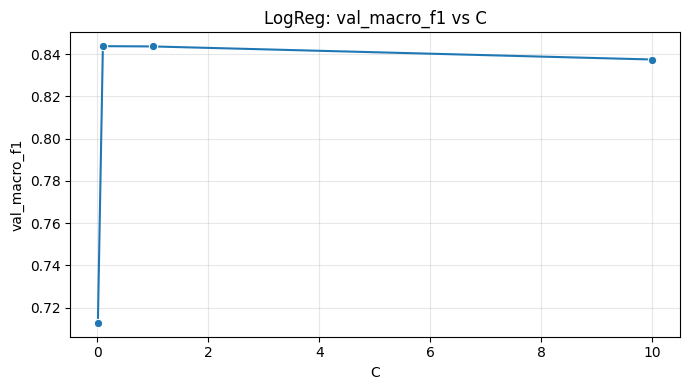

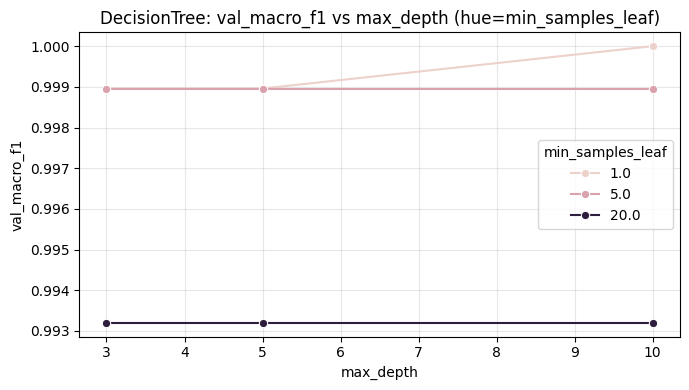

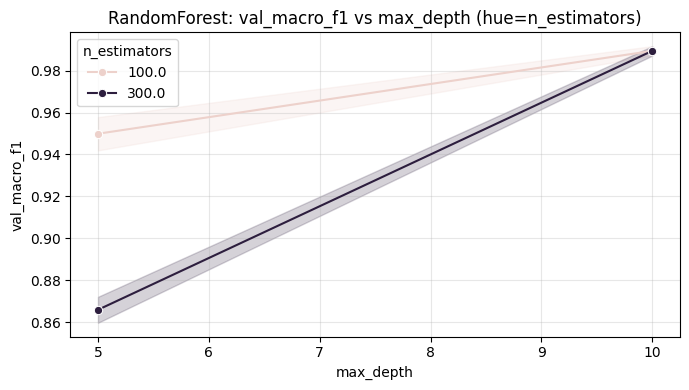

In [31]:
def plot_metric_vs_param(df, model_name, param_x, param_hue=None,
                         metric="val_macro_f1"):
    sub = df[df.model == model_name]
    if sub.empty or param_x not in sub.columns:
        print(f"[skip] {model_name}: нет {param_x}")
        return
    plt.figure(figsize=(7, 4))
    hue = param_hue if (param_hue and param_hue in sub.columns) else None
    sns.lineplot(data=sub, x=param_x, y=metric, hue=hue, marker="o")
    plt.title(f"{model_name}: {metric} vs {param_x}" +
              (f" (hue={param_hue})" if hue else ""))
    plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

plot_metric_vs_param(val_df, "LogReg", "C")
plot_metric_vs_param(val_df, "DecisionTree", "max_depth", "min_samples_leaf")
plot_metric_vs_param(val_df, "RandomForest", "max_depth", "n_estimators")

Графики подтверждают гипотезу: `crop_health` сгенерирован по детерминированной формуле от `soil_moisture` и `temperature`.

- **LogReg:** потолок ~0.84 — линейная модель не может восстановить нелинейные пороги (`<25`, `<40`). Оптимум `C ∈ [1, 8]`, далее плато/просадка.
- **DecisionTree:** уже при `max_depth=3` F1 ≈ 0.999 — дерево полностью восстанавливает исходную формулу. `min_samples_leaf=20` слегка снижает качество (~0.993), но картина та же.
- **RandomForest:** качество линейно растёт с `max_depth` (от ~0.86 при 5 до ~0.985+ при 10). `n_estimators` 100 vs 300 влияет только на малых глубинах.


**Итог:** одиночное дерево глубины 3 — оптимальное и интерпретируемое решение (F1 ≈ 0.999). Логистическая регрессия принципиально ограничена линейностью, а ансамбли требуют избыточной глубины (до 10) для сопоставимого результата.